# 03 Cohort retention analysis

CartPadi Nigeria Ltd. is a fictional marketplace and every row here is synthetic (see notebook 01).

A cohort is every customer whose first purchase fell in the same calendar month. Following each cohort month by month shows whether CartPadi is getting better or worse at keeping the people it wins, and which kinds of customer stay.

Output: `data/processed/cohort_retention.csv`

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cartpadi as cp

cp.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

t = cp.load_clean()
customers, orders, items, products = (t[k] for k in ["customers", "orders", "order_items", "products"])

## 1. Cohorts and activity

Definitions used throughout:

1. A purchase is any order that was not cancelled.
2. A customer's cohort is the month of their first purchase. The 1,163 customers who never completed a purchase have no cohort.
3. Month k is the k-th calendar month after the cohort month. Month 0 is the cohort month itself, so it is always 100%.
4. A customer is active in month k if they made at least one purchase in that month.

Calendar months are used, not 30-day blocks, so the matrix lines up with the Power BI matrix and with the seasonal calendar.

In [2]:
live = orders[orders["order_status"] != "cancelled"].copy()
live["order_month"] = live["order_date"].dt.to_period("M")

first = live.sort_values("order_date").groupby("customer_id").first()
cust = customers.set_index("customer_id").join(
    first[["order_date", "order_month", "payment_method", "order_id"]].rename(
        columns={"order_date": "first_purchase", "order_month": "cohort", "payment_method": "first_payment",
                 "order_id": "first_order_id"}), how="inner")
cust["first_category"] = cust["first_order_id"].map(cp.first_order_category(items, products))
cust["first_delivery_days"] = cust["first_order_id"].map(orders.set_index("order_id")["delivery_days"])

live = live.join(cust["cohort"], on="customer_id")
live["k"] = (live["order_month"] - live["cohort"]).apply(lambda d: d.n)

last_month = pd.Period(cp.SNAPSHOT, "M")
print(f"Customers with a cohort: {len(cust):,}")
print(f"Cohorts: {cust['cohort'].min()} to {cust['cohort'].max()} ({cust['cohort'].nunique()} months)")
cust["cohort"].value_counts().sort_index().to_frame("customers").T

Customers with a cohort: 23,837
Cohorts: 2024-01 to 2025-12 (24 months)


cohort,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,...,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
customers,682,714,772,1038,862,750,862,869,810,885,...,891,1195,973,953,964,999,986,1058,1618,1593


In [3]:
active = live.groupby(["cohort", "k"])["customer_id"].nunique().unstack(fill_value=0)
size = cust.groupby("cohort").size()
retention = active.div(size, axis=0)

# Months that have not happened yet for a cohort are unknown, not zero.
for c in retention.index:
    observable = (last_month - c).n
    retention.loc[c, retention.columns > observable] = np.nan
retention.iloc[:6, :8]

k,0,1,2,3,4,5,6,7
cohort,,,,,,,,
2024-01,1.000,0.252,0.211,0.233,0.191,0.213,0.196,0.189
2024-02,1.000,0.218,0.203,0.179,0.168,0.167,0.171,0.182
2024-03,1.000,0.277,0.214,0.205,0.199,0.207,0.201,0.211
2024-04,1.000,0.232,0.192,0.185,0.199,0.188,0.188,0.259
2024-05,1.000,0.230,0.186,0.189,0.182,0.202,0.249,0.262
2024-06,1.000,0.209,0.191,0.164,0.184,0.228,0.245,0.183


## 2. The retention heatmap

Rows are cohorts, columns are months since first purchase, and the shade is the share of the cohort that bought in that month. Month 0 is left out of the colour scale because it is always 100% and would wash out everything else.

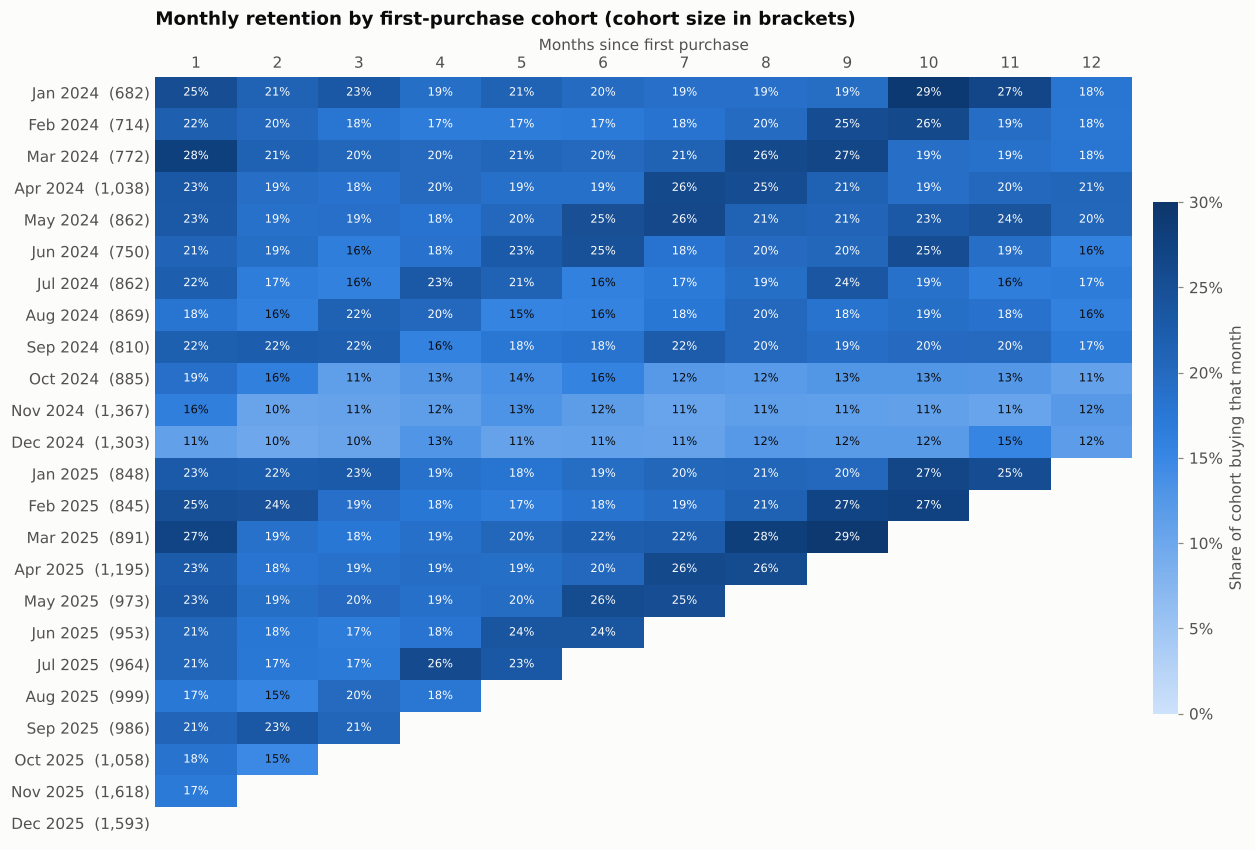

In [4]:
M = 12
view = retention.loc[:, 1:M]

fig, ax = plt.subplots(figsize=(12, 9))
vmax = 0.30
img = ax.imshow(view.to_numpy(), cmap=cp.SEQ_CMAP, vmin=0, vmax=vmax, aspect="auto")
for i in range(view.shape[0]):
    for j in range(view.shape[1]):
        v = view.iat[i, j]
        if np.isnan(v):
            continue
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                color="white" if v > vmax * 0.55 else cp.INK)
ax.set_xticks(range(M), [str(k) for k in range(1, M + 1)])
ax.set_yticks(range(len(view)), [f"{p.strftime('%b %Y')}  ({size[p]:,})" for p in view.index])
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Months since first purchase")
ax.tick_params(length=0)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
cbar = fig.colorbar(img, ax=ax, fraction=0.025, pad=0.02, format=lambda v, _: f"{v:.0%}")
cbar.outline.set_visible(False)
cbar.set_label("Share of cohort buying that month", color=cp.INK_2)
ax.set_title("Monthly retention by first-purchase cohort (cohort size in brackets)", pad=34)
cp.save(fig, "03_retention_heatmap")
plt.show()

Three things stand out.

1. The loss happens before month 1. Only about one customer in five buys in the month after their first purchase. After that the share barely moves: a core of regular buyers keeps ordering most months, and almost everyone else is already gone.
2. The October to December 2024 cohorts sit in a pale band, at 10% to 16% where other cohorts run at about 20%. The customers won in the festive rush were the weakest CartPadi signed up all year.
3. The darker diagonal cells are the calendar at work. Every cohort lights up when its row crosses a November or December, whatever its age: the March 2024 cohort ran at 20% in its month 3 (June) and 26% to 27% in months 8 and 9 (November and December).

## 3. Average retention curve

Each month's average is weighted by cohort size and uses only the cohorts that have reached that month, so the later points rest on fewer, older cohorts.

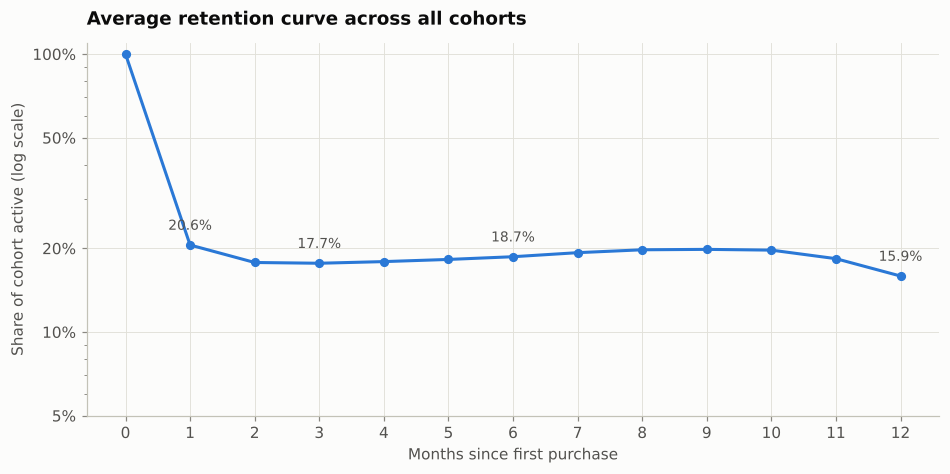

k,0,1,2,3,4,5,6,7,8,9,10,11,12
retention,1.000,0.206,0.178,0.177,0.179,0.182,0.187,0.193,0.198,0.198,0.197,0.184,0.159
cohorts_in_average,24.000,23.000,22.000,21.000,20.000,19.000,18.000,17.000,16.000,15.000,14.000,13.000,12.000


In [5]:
weights = retention.notna().mul(size, axis=0)
curve = (retention.fillna(0) * weights).sum() / weights.sum()
n_cohorts = retention.notna().sum()
curve = curve.loc[:M]

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(curve.index, curve.values, marker="o", markersize=5, color=cp.SERIES[0])
for k in [1, 3, 6, 12]:
    ax.annotate(f"{curve[k]:.1%}", (k, curve[k]), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, color=cp.INK_2)
ax.set_yscale("log")
ax.set_yticks([0.05, 0.1, 0.2, 0.5, 1.0], ["5%", "10%", "20%", "50%", "100%"])
ax.set_xticks(range(0, M + 1))
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Share of cohort active (log scale)")
ax.set_title("Average retention curve across all cohorts")
cp.save(fig, "03_retention_curve")
plt.show()

pd.DataFrame({"retention": curve, "cohorts_in_average": n_cohorts.loc[:M]}).T

## 4. 30, 60 and 90-day retention

The monthly view depends on where in the month a customer started. The benchmark numbers below count days instead: the share of customers who made a second purchase within 30, 60 and 90 days of the first. Each benchmark only counts customers whose first purchase was at least that many days before the snapshot.

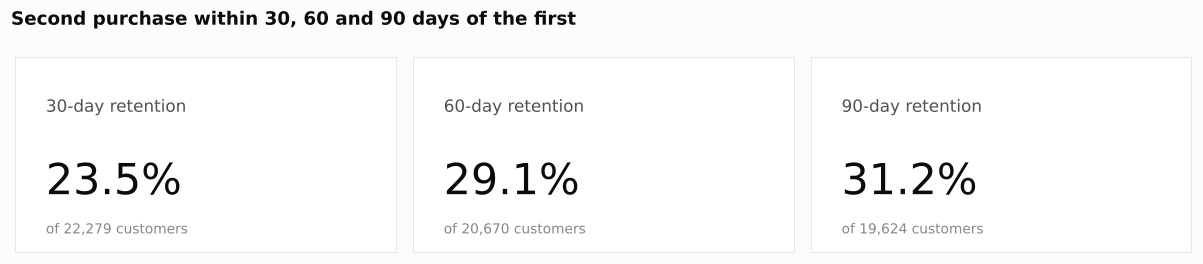

Median days to second purchase: 29
Customers who ever made a second purchase: 44.9%
Of those, came back after 90 days: 34.9%


In [6]:
ordered = live.sort_values("order_date")
second = ordered[ordered.groupby("customer_id").cumcount() == 1].set_index("customer_id")["order_date"]
cust["days_to_second"] = (second.reindex(cust.index) - cust["first_purchase"]).dt.days


def repeat_within(df, days):
    mature = df[df["first_purchase"] < cp.SNAPSHOT_END - pd.Timedelta(days=days)]
    return mature["days_to_second"].le(days).mean(), len(mature)


bench = {d: repeat_within(cust, d) for d in (30, 60, 90)}

fig, axes = plt.subplots(1, 3, figsize=(11, 2.4))
for ax, (d, (rate, n)) in zip(axes, bench.items()):
    ax.set_axis_off()
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor="white",
                               edgecolor=cp.GRID, linewidth=1))
    ax.text(0.08, 0.72, f"{d}-day retention", fontsize=11, color=cp.INK_2, transform=ax.transAxes)
    ax.text(0.08, 0.30, f"{rate:.1%}", fontsize=28, color=cp.INK, transform=ax.transAxes)
    ax.text(0.08, 0.10, f"of {n:,} customers", fontsize=9, color=cp.MUTED, transform=ax.transAxes)
fig.suptitle("Second purchase within 30, 60 and 90 days of the first", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
cp.save(fig, "03_retention_kpis")
plt.show()

print(f"Median days to second purchase: {cust['days_to_second'].median():.0f}")
print(f"Customers who ever made a second purchase: {cust['days_to_second'].notna().mean():.1%}")
print(f"Of those, came back after 90 days: {(cust['days_to_second'] > 90).sum() / cust['days_to_second'].notna().sum():.1%}")

## 5. Retention by acquisition channel

For segment comparisons a cumulative curve reads better than monthly activity: the share of each group that has made a second purchase by month k. It only rises, so the lines don't tangle. To keep the comparison fair, only cohorts with at least 12 months of history are used (first purchase in or before December 2024).

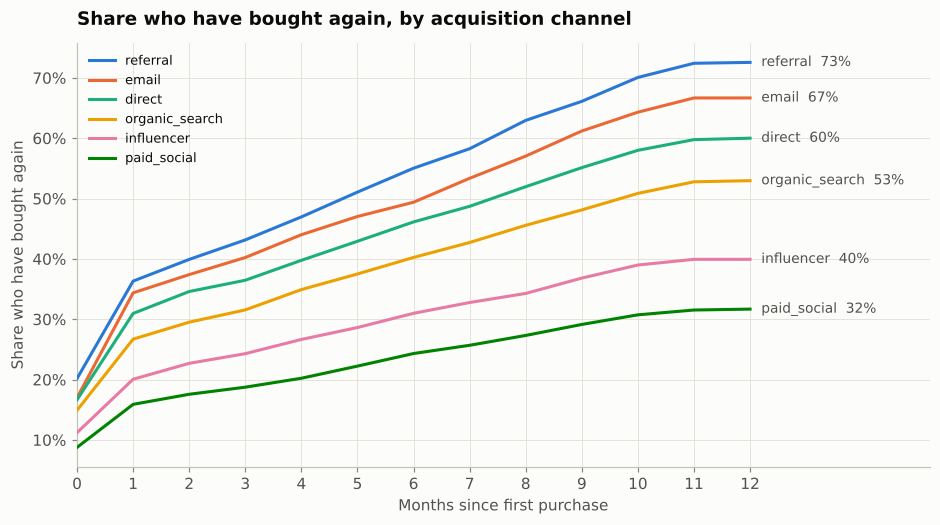

,customers,by_month_1,by_month_3,by_month_12,repeat_within_90_days
referral,"1,363",36.3%,43.1%,72.6%,43.0%
email,"1,059",34.4%,40.2%,66.7%,39.8%
direct,"2,090",31.0%,36.5%,60.0%,36.1%
organic_search,"2,704",26.7%,31.5%,53.0%,32.4%
influencer,"1,062",20.1%,24.3%,39.9%,24.1%
paid_social,"2,636",15.9%,18.7%,31.7%,19.4%


In [7]:
def cumulative_repeat(df, group, months=12):
    cutoff = last_month - months
    base = df[df["cohort"] <= cutoff].copy()
    # Months from first purchase to second purchase, on the same calendar-month basis as the heatmap.
    second_month = (base["first_purchase"] + pd.to_timedelta(base["days_to_second"], unit="D")).dt.to_period("M")
    base["k2"] = [(s - c).n if pd.notna(s) else np.nan for s, c in zip(second_month, base["cohort"])]
    out = {}
    for g, sub in base.groupby(group):
        out[g] = [(sub["k2"] <= k).mean() for k in range(months + 1)]
    return pd.DataFrame(out, index=range(months + 1)), base[group].value_counts()


def plot_curves(curves, order, title, fname, highlight=None):
    fig, ax = plt.subplots(figsize=(10, 5))
    slot = 0
    ends = []
    for g in order:
        if highlight is None or g in highlight:
            color, lw, z = cp.SERIES[slot], 2, 3
            slot += 1
            ends.append((curves[g].iloc[-1], g, color))
        else:
            color, lw, z = cp.NEUTRAL, 1.5, 2
        ax.plot(curves.index, curves[g], color=color, linewidth=lw, zorder=z, label=g)
    # End labels, nudged apart so they never overlap.
    ends.sort()
    gap = 0.025
    placed = []
    for v, g, color in ends:
        y = max(v, placed[-1] + gap) if placed else v
        placed.append(y)
        ax.text(curves.index[-1] + 0.2, y, f"{g}  {v:.0%}", va="center", fontsize=9, color=cp.INK_2)
    ax.set_xlim(0, curves.index[-1] + 3.2)
    ax.set_xticks(range(0, curves.index[-1] + 1))
    cp.pct_axis(ax)
    ax.set_xlabel("Months since first purchase")
    ax.set_ylabel("Share who have bought again")
    ax.set_title(title)
    ax.legend(loc="upper left", fontsize=8.5)
    cp.save(fig, fname)
    plt.show()


ch_curves, ch_n = cumulative_repeat(cust, "acquisition_channel")
ch_order = ch_curves.iloc[-1].sort_values(ascending=False).index
plot_curves(ch_curves, ch_order, "Share who have bought again, by acquisition channel", "03_repeat_by_channel")

ch_table = pd.DataFrame({
    "customers": ch_n,
    "by_month_1": ch_curves.loc[1], "by_month_3": ch_curves.loc[3], "by_month_12": ch_curves.loc[12],
    "repeat_within_90_days": cust[cust["first_purchase"] < cp.SNAPSHOT_END - pd.Timedelta(days=90)]
        .groupby("acquisition_channel")["days_to_second"].apply(lambda s: s.le(90).mean()),
}).loc[ch_order]
ch_table.style.format({"customers": "{:,}", **{c: "{:.1%}" for c in ch_table.columns[1:]}})

## 6. Retention by first category

Electronics, Fashion and Beauty and Skincare are picked out; the other three categories are in grey for context.

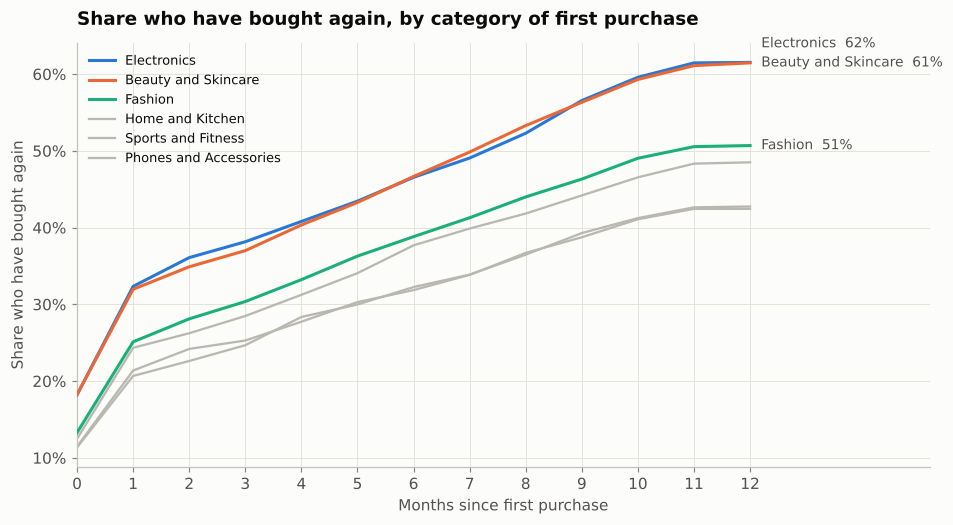

,customers,by_month_3,by_month_12,avg_spend_to_date
Electronics,"1,549",38.2%,61.5%,N792.8k
Beauty and Skincare,"1,946",37.0%,61.5%,N243.8k
Fashion,"2,839",30.4%,50.7%,N236.0k
Home and Kitchen,"1,738",28.5%,48.5%,N247.1k
Sports and Fitness,924,24.7%,42.7%,N256.3k
Phones and Accessories,"1,918",25.3%,42.4%,N513.7k


In [8]:
cat_curves, cat_n = cumulative_repeat(cust, "first_category")
cat_order = cat_curves.iloc[-1].sort_values(ascending=False).index
plot_curves(cat_curves, cat_order, "Share who have bought again, by category of first purchase",
            "03_repeat_by_category", highlight=["Beauty and Skincare", "Electronics", "Fashion"])

spend = live.groupby("customer_id")["order_total_ngn"].sum()
cat_table = pd.DataFrame({
    "customers": cat_n,
    "by_month_3": cat_curves.loc[3], "by_month_12": cat_curves.loc[12],
    "avg_spend_to_date": cust.join(spend.rename("spend")).groupby("first_category")["spend"].mean(),
}).loc[cat_order]
cat_table.style.format({"customers": "{:,}", "by_month_3": "{:.1%}", "by_month_12": "{:.1%}",
                        "avg_spend_to_date": cp.naira})

## 7. Payment method and delivery speed

Two operational levers sit in the first order: how the customer paid and how long the parcel took. Both are shown as 90-day repeat rates.

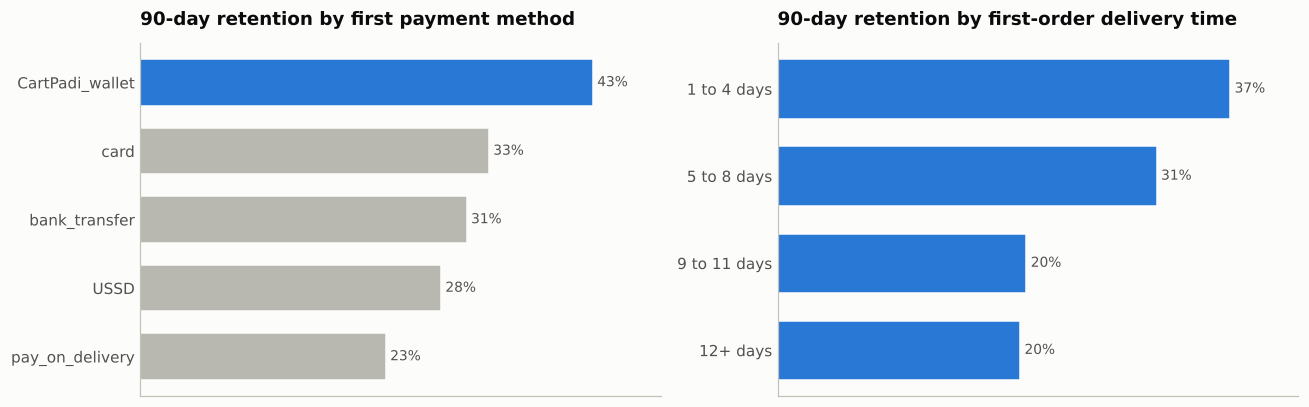

                 mean   size
region                      
Rest of Nigeria 0.199   4570
Top 5 states    0.346  15054

                               mean  size
region          delivery_band            
Rest of Nigeria 1 to 4 days   0.152    66
                5 to 8 days   0.214   631
                9 to 11 days  0.204  1875
                12+ days      0.192  1998
Top 5 states    1 to 4 days   0.373  7956
                5 to 8 days   0.320  6797
                9 to 11 days  0.200   240
                12+ days      0.426    61


In [9]:
mature90 = cust[cust["first_purchase"] < cp.SNAPSHOT_END - pd.Timedelta(days=90)].copy()
mature90["ret90"] = mature90["days_to_second"].le(90)
mature90["delivery_band"] = pd.cut(mature90["first_delivery_days"], [0, 4, 8, 11, 20],
                                   labels=["1 to 4 days", "5 to 8 days", "9 to 11 days", "12+ days"])
mature90["region"] = np.where(mature90["state"].isin(cp.TOP5_STATES), "Top 5 states", "Rest of Nigeria")

pay = mature90.groupby("first_payment")["ret90"].mean().sort_values(ascending=False)
dlv = mature90.groupby("delivery_band", observed=True)["ret90"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cp.hbar(axes[0], pay.index, pay.values, fmt=lambda v: f"{v:.0%}", highlight="CartPadi_wallet")
axes[0].set_title("90-day retention by first payment method")
axes[0].set_xticks([])
cp.hbar(axes[1], dlv.index, dlv.values, fmt=lambda v: f"{v:.0%}")
axes[1].set_title("90-day retention by first-order delivery time")
axes[1].set_xticks([])
fig.tight_layout()
cp.save(fig, "03_payment_delivery")
plt.show()

print(mature90.groupby("region")["ret90"].agg(["mean", "size"]).to_string())
print()
print(mature90.groupby(["region", "delivery_band"], observed=True)["ret90"].agg(["mean", "size"]).to_string())

Wallet payers come back at about twice the rate of pay-on-delivery customers.

Delivery time and region move together, so this data can't fully separate them. Almost every slow first delivery went outside the top five states, and almost every fast one went inside them. The clean comparison sits inside the top five states: customers whose first parcel took 1 to 4 days returned at about 37%, against about 20% for the 240 whose parcel took 9 to 11 days. The 12+ day group inside the top five is too small (61 customers) to read.

## 8. Lifetime value by cohort

Comparing total spend across cohorts is unfair: older cohorts have had longer to spend. So each cohort is measured at the same age: cumulative spend per customer by month 3 and month 6 after first purchase, in naira. Only cohorts old enough are shown.

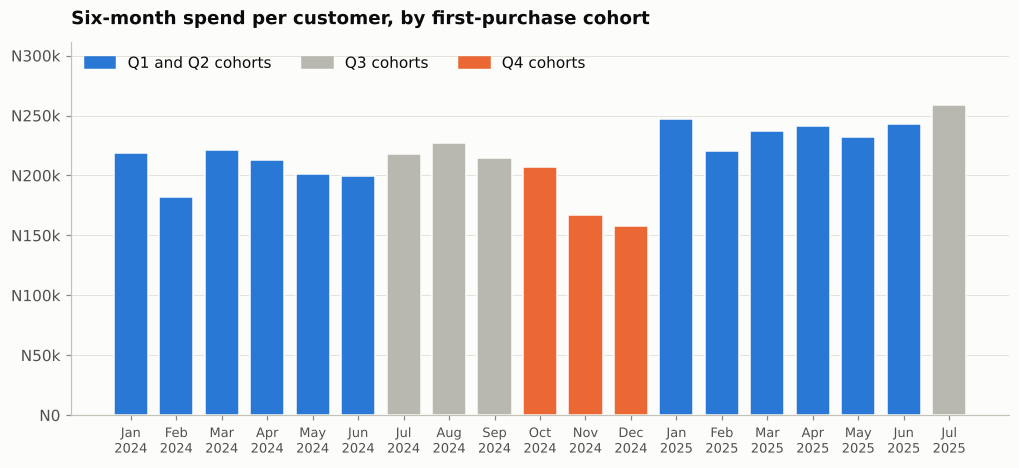

,ltv_3m,ltv_6m,repeat_within_90_days
Q1-Q2,N147.5k,N223.0k,33.8%
Q3,N135.9k,N230.7k,31.2%
Q4,N129.6k,N173.4k,23.7%


In [10]:
rev = live.groupby(["cohort", "k"])["order_total_ngn"].sum().unstack(fill_value=0)
cum_ltv = rev.cumsum(axis=1).div(size, axis=0)
for c in cum_ltv.index:
    cum_ltv.loc[c, cum_ltv.columns > (last_month - c).n] = np.nan

ltv6 = cum_ltv[5].dropna()  # months 0 to 5 = first six months
q = ltv6.index.quarter
colors = [cp.SERIES[1] if qq == 4 else cp.SERIES[0] if qq in (1, 2) else cp.NEUTRAL for qq in q]

fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(len(ltv6))
ax.bar(x, ltv6.values, color=colors, width=0.75, edgecolor=cp.SURFACE)
ax.set_xticks(x, [p.strftime("%b\n%Y") for p in ltv6.index], fontsize=8.5)
ax.grid(axis="x", visible=False)
cp.naira_axis(ax)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=cp.SERIES[0], label="Q1 and Q2 cohorts"), Patch(color=cp.NEUTRAL, label="Q3 cohorts"),
                   Patch(color=cp.SERIES[1], label="Q4 cohorts")], loc="upper left", ncols=3)
ax.set_ylim(0, ltv6.max() * 1.2)
ax.set_title("Six-month spend per customer, by first-purchase cohort")
cp.save(fig, "03_ltv_by_cohort")
plt.show()

quarter_group = pd.Series(np.select([q.isin([1, 2]), q == 3], ["Q1-Q2", "Q3"], "Q4"), index=ltv6.index)
qt = pd.DataFrame({
    "ltv_3m": cum_ltv[2].groupby(quarter_group).apply(lambda s: np.average(s, weights=size[s.index])),
    "ltv_6m": ltv6.groupby(quarter_group).apply(lambda s: np.average(s, weights=size[s.index])),
})
mature90["q"] = np.select([mature90["cohort"].dt.quarter.isin([1, 2]), mature90["cohort"].dt.quarter == 3],
                          ["Q1-Q2", "Q3"], "Q4")
qt["repeat_within_90_days"] = mature90.groupby("q")["ret90"].mean()
qt.style.format({"ltv_3m": cp.naira, "ltv_6m": cp.naira, "repeat_within_90_days": "{:.1%}"})

In [11]:
q12, q4 = qt.loc["Q1-Q2", "repeat_within_90_days"], qt.loc["Q4", "repeat_within_90_days"]
print(f"Q4 cohorts repeat within 90 days {1 - q4 / q12:.0%} less often than Q1-Q2 cohorts.")
print(f"Six-month spend per customer: Q4 {cp.naira(qt.loc['Q4', 'ltv_6m'])} vs Q1-Q2 {cp.naira(qt.loc['Q1-Q2', 'ltv_6m'])}.")

disc = orders.join(cust["cohort"], on="customer_id")
disc = disc[disc["order_id"].isin(cust["first_order_id"])]
disc["disc_share"] = disc["discount_ngn"] / (disc["order_total_ngn"] + disc["discount_ngn"])
disc["q"] = np.where(disc["cohort"].dt.quarter == 4, "Q4", "Q1-Q3")
print("\nDiscount as a share of first-order value:")
print(disc.groupby("q")["disc_share"].mean().map("{:.1%}".format).to_string())

Q4 cohorts repeat within 90 days 30% less often than Q1-Q2 cohorts.
Six-month spend per customer: Q4 N173.4k vs Q1-Q2 N223.0k.

Discount as a share of first-order value:
q
Q1-Q3    2.1%
Q4       8.9%


Note on the cohort grouping: Q4 here means a first purchase in October, November or December. The generator assigned the Q4 effect by signup quarter, and nearly all customers buy on or soon after signup, so the two line up.

## 9. Export

Long format, one row per cohort and month, so Power BI can build the matrix and the curves from one table.

In [12]:
out = (retention.stack(future_stack=True).rename("retention_rate").to_frame()
       .join(active.stack().rename("active_customers"))
       .join(cum_ltv.stack(future_stack=True).rename("cumulative_revenue_per_customer_ngn")))
out = out.reset_index().rename(columns={"k": "months_since_first_purchase", "cohort": "cohort_month"})
out = out[out["retention_rate"].notna()]
out["active_customers"] = out["active_customers"].fillna(0).astype(int)
out["cohort_size"] = out["cohort_month"].map(size)
out["cohort_quarter"] = "Q" + out["cohort_month"].dt.quarter.astype(str)
out["cohort_month"] = out["cohort_month"].dt.strftime("%Y-%m")
out = out[["cohort_month", "cohort_quarter", "cohort_size", "months_since_first_purchase", "active_customers",
           "retention_rate", "cumulative_revenue_per_customer_ngn"]]
out.to_csv(cp.PROCESSED / "cohort_retention.csv", index=False)
print(f"Wrote {len(out):,} rows to data/processed/cohort_retention.csv")
out.head(14)

Wrote 300 rows to data/processed/cohort_retention.csv


,cohort_month,cohort_quarter,cohort_size,months_since_first_purchase,active_customers,retention_rate,cumulative_revenue_per_customer_ngn
0,2024-01,Q1,682,0,682,1.000,"84,923.032"
1,2024-01,Q1,682,1,172,0.252,"113,181.125"
2,2024-01,Q1,682,2,144,0.211,"138,577.192"
3,2024-01,Q1,682,3,159,0.233,"173,701.697"
4,2024-01,Q1,682,4,130,0.191,"196,344.318"
5,2024-01,Q1,682,5,145,0.213,"219,044.938"
6,2024-01,Q1,682,6,134,0.196,"237,032.152"
7,2024-01,Q1,682,7,129,0.189,"262,214.432"
8,2024-01,Q1,682,8,129,0.189,"289,097.122"
9,2024-01,Q1,682,9,132,0.194,"321,094.388"


## Findings

1. CartPadi loses most of its customers at the first hurdle. 23.5% buy again within 30 days and 31.2% within 90 days. After month 1, the share of a cohort buying each month holds at about 18% to 20% for a year: the regulars stay and everyone else has left. Retention work should target the weeks right after the first order.
2. Not every lapse is final. 44.9% of customers eventually make a second purchase, and 34.9% of those come back more than 90 days later, often for the next sale season. A 90-day churn flag will mark some of these as lost when they are only slow.
3. Channel quality differs by a factor of two. Referral customers repeat within 90 days at 43% and paid social at 19%. A year in, 73% of referral customers have bought again against 32% from paid social. Paid social brings in about a quarter of new customers, so this gap is a budget question.
4. Festive-season customers are weaker. October to December cohorts repeat within 90 days 30% less often than January to June cohorts (23.7% against 33.8%), and spend 22% less per head in their first six months (N173.4k against N223.0k). Their first orders carried four times the discount (8.9% of order value against 2.1%). They came for the deal.
5. The first order shapes the second. Customers whose first purchase was Electronics or Beauty and Skincare are the most likely to return, and Electronics first-buyers have spent 3.4 times as much as Fashion first-buyers (N792.8k against N236.0k). Wallet payers return at 42% against 22% for pay on delivery. Outside the top five states, where parcels take 9 to 14 days, 90-day retention is 20% against 35% inside them.